# Adaptive Sparsity Research

Compare dense and sparse models. Edit settings below.


## Review revision
Training enables controls with matching deployed MACs and weight bytes.
Displayed saved results remain the historical pilot unless RUN_TRAINING is enabled.
The intended appliance mapping is recorded in ../label_schema.json and remains source-unverified.
See docs/PROTOCOL.md for metric definitions, algorithm order, uncertainty and deployment accounting.


In [ ]:
from pathlib import Path
import os, csv, sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "adaptive_sparsity/research_set.py").is_file())
sys.path.insert(0, str(ROOT / "adaptive_sparsity"))
from research_set import Config, run_experiment, MATCHED

MODE = "pilot"  # smoke, pilot, full
RUN_TRAINING = False
MATCHED_CONTROLS = True
REQUIRE_VERIFIED_LABELS = False  # Source records are still missing.
DATA_DIR = Path(os.environ.get("SET_DATA_DIR", str(ROOT / "data and requirements")))
METADATA = None  # Optional source-group CSV.
RUN_DIR = ROOT / "adaptive_sparsity" / "runs" / (MODE + "_review")
cfg = Config.full() if MODE == "full" else Config.pilot() if MODE == "pilot" else Config()

cfg.require_verified_labels = REQUIRE_VERIFIED_LABELS
if MATCHED_CONTROLS:
    cfg.methods = tuple(dict.fromkeys((*cfg.methods, "adaptive_group_set", *sorted(MATCHED))))

if RUN_TRAINING:
    run_experiment(DATA_DIR, RUN_DIR, cfg, METADATA)
    score_file = RUN_DIR / "metrics.csv"
else:
    score_file = ROOT / "adaptive_sparsity/results.csv"
with score_file.open() as handle:
    rows = list(csv.DictReader(handle))
print(f"Loaded {len(rows)} runs from {score_file}.")


## Results

F1 is averaged across targets, then seeds. Error bars show seed variation.


Model,Method,F1 ± SD,Neurons,Weights KiB
DNN,group_lasso,0.8013 ± 0.0056,100.0,242.7
DNN,fixed_group_set,0.7926 ± 0.0022,90.0,218.5
DNN,adaptive_gradient_set,0.7952 ± 0.0014,100.0,242.7
DNN,lasso,0.7989 ± 0.0035,100.0,242.7
DNN,gradient_set,0.7935 ± 0.0018,100.0,242.7
DNN,adaptive_structured_set,0.7904 ± 0.0039,76.3,185.3
DNN,fixed_set,0.7971 ± 0.0059,100.0,242.7
DNN,set_lasso,0.7936 ± 0.0052,100.0,242.7
DNN,adaptive_group_set,0.7934 ± 0.0054,76.7,186.1
DNN,static_sparse,0.7988 ± 0.0016,100.0,242.7


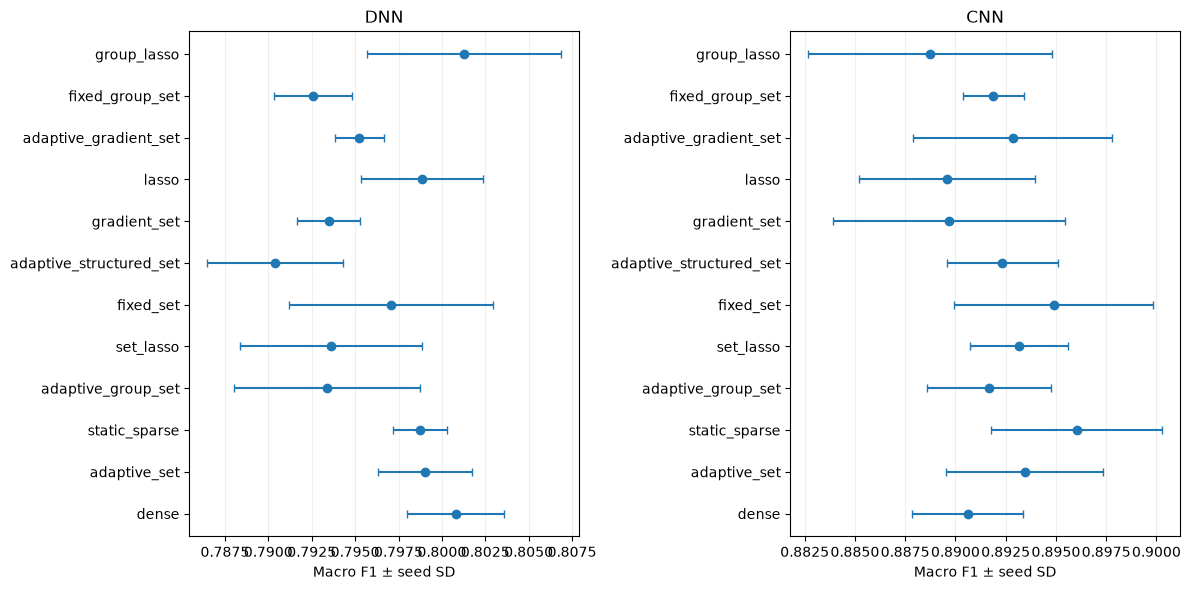

In [2]:
methods = list(dict.fromkeys(r["method"] for r in rows))
architectures = list(dict.fromkeys(r["architecture"] for r in rows))
summary = []
for architecture in architectures:
    for method in methods:
        group = [r for r in rows if r["architecture"] == architecture and r["method"] == method]
        seeds = sorted({r["seed"] for r in group})
        scores = [np.mean([float(r["f1"]) for r in group if r["seed"] == seed]) for seed in seeds]
        summary.append(dict(backbone=architecture, method=method,
            f1=float(np.mean(scores)), sd=float(np.std(scores, ddof=1)) if len(scores)>1 else 0.,
            neurons=float(np.mean([float(r["selected_neurons"]) for r in group])),
            weight_kib=float(np.mean([float(r["compact_weight_bytes"]) for r in group]))/1024))

import html
header = "<tr><th>Model</th><th>Method</th><th>F1 ± SD</th><th>Neurons</th><th>Weights KiB</th></tr>"
body = "".join(f"<tr><td>{html.escape(r['backbone'])}</td><td>{html.escape(r['method'])}</td>"
    f"<td>{r['f1']:.4f} ± {r['sd']:.4f}</td><td>{r['neurons']:.1f}</td><td>{r['weight_kib']:.1f}</td></tr>" for r in summary)
display(HTML("<table>" + header + body + "</table>"))

fig, axes = plt.subplots(1, len(architectures), figsize=(12, 6), squeeze=False)
for ax, architecture in zip(axes[0], architectures):
    group = [r for r in summary if r["backbone"] == architecture]
    ax.errorbar([r["f1"] for r in group], range(len(group)), xerr=[r["sd"] for r in group], fmt="o", capsize=3)
    ax.set_yticks(range(len(group)), [r["method"] for r in group])
    ax.invert_yaxis()
    ax.set(title=architecture, xlabel="Macro F1 ± seed SD")
    ax.grid(axis="x", alpha=.2)
plt.tight_layout()
plt.show()


## Limits

Pilot results are exploratory. Source independence and publication readiness are unverified. See ../README.md.

## New-run diagnostics
A fresh run writes label_prevalence.csv, macro_metrics.csv, paired_macro_uncertainty.csv,
paired_uncertainty.csv, convergence_diagnostics.csv and metric_protocol.json.
Each model has learning-curve PNGs, per-tensor storage JSON, held-out predictions and a native .keras export.
Smoke runs verify the workflow; they do not establish accuracy or deployment gains.
